Có 2 hướng chính để biến ảnh thành vector đặc trưng (feature vector) làm input cho mô hình học máy: trích xuất thủ công (handcrafted) dựa trên các thuật toán xử lý ảnh cổ điển, và trích xuất embedding bằng mạng deep learning.

### Nhóm 1: Trích xuất đặc trưng thủ công
#### 1. HOG (Histogram of Oriented Gradients)
HOG tính toán hướng và độ lớn của độ sáng (gradient) trên từng ô nhỏ. Phương pháp này mô tả rất tốt dáng vẻ (shape) và biên độ (contour) của con người khi thực hiện hành động (như chạy, nhảy, đá bóng).

[HOG] Feature Vector Shape: (16740,)


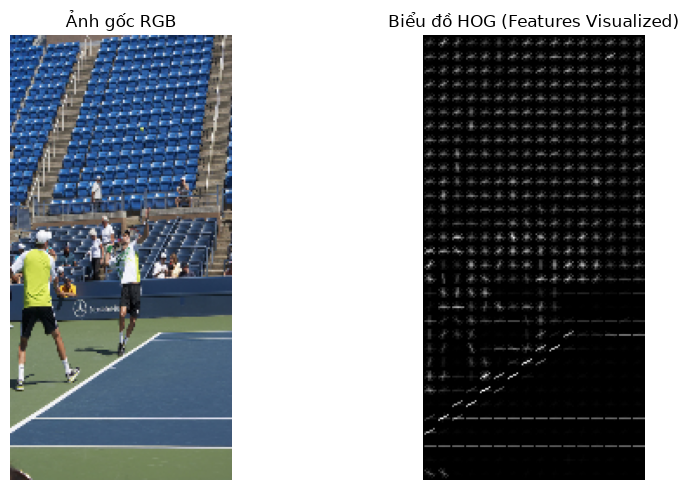

In [18]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from skimage.feature import hog

def extract_and_visualize_hog(image_path):
    # 1. Đọc ảnh RGB và chuyển sang Gray
    image_bgr = cv2.imread(image_path)
    image_rgb = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2RGB)
    gray = cv2.cvtColor(image_rgb, cv2.COLOR_RGB2GRAY)
    gray = cv2.resize(gray, (128, 256)) # Resize chuẩn cho dáng người

    # 2. Trích xuất HOG
    features, hog_image = hog(
        gray,
        orientations=9,
        pixels_per_cell=(8, 8),
        cells_per_block=(2, 2),
        visualize=True,
        block_norm='L2-Hys'
    )

    print(f"[HOG] Feature Vector Shape: {features.shape}")

    # 3. Visualize
    fig, axes = plt.subplots(1, 2, figsize=(10, 5))
    axes[0].imshow(cv2.resize(image_rgb, (128, 256)))
    axes[0].set_title("Ảnh gốc RGB")
    axes[0].axis('off')

    axes[1].imshow(hog_image, cmap='gray')
    axes[1].set_title("Biểu đồ HOG (Features Visualized)")
    axes[1].axis('off')
    plt.tight_layout()
    plt.show()

    return features

# Chạy thử
hog_vec = extract_and_visualize_hog("../v-coco/vcoco_samples/COCO_train2014_000000318637.jpg")

#### 2. Kết hợp LBP (Texture) + Color Histogram (Màu bối cảnh)
LBP mô tả bề mặt kết cấu (quần áo, dụng cụ thao tác), còn Color Histogram giúp mô hình phân biệt bối cảnh (sân cỏ, hồ bơi, phòng gym).

[LBP + Color] Feature Vector Shape: (58,)


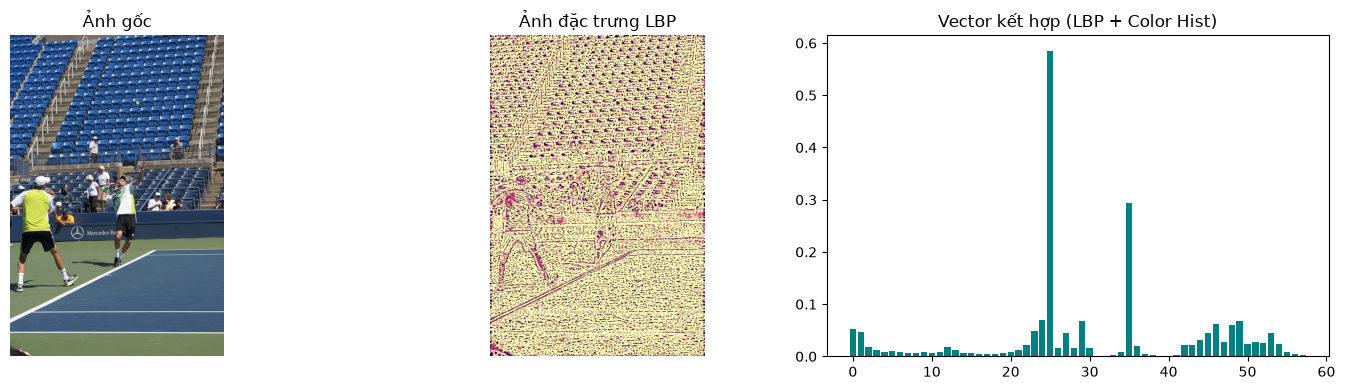

In [20]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from skimage.feature import local_binary_pattern

def extract_and_visualize_lbp_color(image_path):
    image_bgr = cv2.imread(image_path)
    image_rgb = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2RGB)
    gray = cv2.cvtColor(image_rgb, cv2.COLOR_RGB2GRAY)

    # 1. Trích xuất LBP (Texture)
    radius = 3
    n_points = 8 * radius
    lbp = local_binary_pattern(gray, n_points, radius, method='uniform')
    (lbp_hist, _) = np.histogram(lbp.ravel(), bins=np.arange(0, n_points + 3), range=(0, n_points + 2))
    lbp_hist = lbp_hist.astype("float")
    lbp_hist /= (lbp_hist.sum() + 1e-6) # Normalize

    # 2. Trích xuất Color Histogram (HSV Space)
    hsv = cv2.cvtColor(image_rgb, cv2.COLOR_RGB2HSV)
    hist_h = cv2.calcHist([hsv], [0], None, [16], [0, 180])
    hist_s = cv2.calcHist([hsv], [1], None, [16], [0, 256])
    color_features = np.concatenate([hist_h, hist_s]).flatten()
    color_features /= (color_features.sum() + 1e-6)

    # Ghép vector đặc trưng
    final_embedding = np.concatenate([lbp_hist, color_features])
    print(f"[LBP + Color] Feature Vector Shape: {final_embedding.shape}")

    # 3. Visualize
    fig, axes = plt.subplots(1, 3, figsize=(15, 4))
    axes[0].imshow(image_rgb)
    axes[0].set_title("Ảnh gốc")
    axes[0].axis('off')

    axes[1].imshow(lbp, cmap='magma')
    axes[1].set_title("Ảnh đặc trưng LBP")
    axes[1].axis('off')

    axes[2].bar(range(len(final_embedding)), final_embedding, color='teal')
    axes[2].set_title("Vector kết hợp (LBP + Color Hist)")
    
    plt.tight_layout()
    plt.show()

    return final_embedding

# Chạy thử
lbp_color_vec = extract_and_visualize_lbp_color("../v-coco/vcoco_samples/COCO_train2014_000000318637.jpg")

### Nhóm 2: Trích xuất Embedding bằng Deep Learning

#### 3. Transfer learning từ CNN pretrained
- Ví dụ: ResNet, VGG, EfficientNet, MobileNet
- Phù hợp: Classification, feature nhanh chóng không cần train lại

In [22]:
import torch
import numpy as np
from PIL import Image
import torchvision.transforms as T
import torchvision.models as models

In [29]:
# Tiền xử lý ảnh dùng chung cho các mô hình torchvision (ResNet/VGG/
# EfficientNet/MobileNet đều được train trên ImageNet nên dùng chung cách
# resize + normalize theo chuẩn ImageNet).

# Chọn device: MPS -> CPU

if torch.backends.mps.is_available():
    device = torch.device("mps")
    print("Using Apple GPU: MPS")
else:
    device = torch.device("cpu")
    print("Using CPU")

_imagenet_transform = T.Compose([
    T.Resize(256),
    T.CenterCrop(224),
    T.ToTensor(),
    T.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225])
])

def _load_image_tensor(img_path):
    """Đọc ảnh từ đường dẫn, trả về tensor shape (1, 3, 224, 224)."""
    img = Image.open(img_path).convert("RGB")
    x = _imagenet_transform(img).unsqueeze(0)
    return x.to(device)

Using Apple GPU: MPS


In [ ]:
def embed_resnet(img_path):
    """
    Trích embedding bằng ResNet50 (pretrained ImageNet).
    Output: vector numpy 2048 chiều (đầu ra của lớp global average pooling,
    trước lớp fully-connected phân loại).
    """
    # Load model Resnet50 pretrained ImageNet
    model = models.resnet50(pretrained=True)
    model.fc = torch.nn.Identity()  # Loại bỏ lớp fully-connected cuối cùng, giữ lại output của global average pooling
    model = model.to(device)
    model.eval()  # Chuyển sang chế độ inference

    x = _load_image_tensor(img_path)  # Tensor shape (1, 3, 224, 224)
    with torch.no_grad():
        embedding = model(x)
    
    return embedding.squeeze(0).cpu().numpy() # Trả về vector numpy shape (2048,)

In [31]:
# 2. VGG16
def embed_vgg(img_path):
    """
    Trích embedding bằng VGG16 (pretrained ImageNet).
    Output: vector numpy 4096 chiều (đầu ra lớp fully-connected áp chót,
    trước lớp phân loại 1000 lớp cuối cùng).
    """
    model = models.vgg16(weights=models.VGG16_Weights.DEFAULT)
    # classifier gồm 7 lớp; bỏ lớp cuối (index 6) -> giữ lại vector 4096-d
    model.classifier = torch.nn.Sequential(*list(model.classifier.children())[:-1])
    model = model.to(device)
    model.eval()
 
    x = _load_image_tensor(img_path)
    with torch.no_grad():
        embedding = model(x)
 
    return embedding.squeeze(0).cpu().numpy()   # shape: (4096,)

In [32]:
# 3. EfficientNet-B0
def embed_efficientnet(img_path):
    """
    Trích embedding bằng EfficientNet-B0 (pretrained ImageNet).
    Output: vector numpy 1280 chiều (đầu ra sau global pooling,
    trước lớp classifier).
    """
    model = models.efficientnet_b0(weights=models.EfficientNet_B0_Weights.DEFAULT)
    model.classifier = torch.nn.Identity()   # bỏ lớp phân loại cuối
    model = model.to(device)
    model.eval()
 
    x = _load_image_tensor(img_path)
    with torch.no_grad():
        embedding = model(x)
 
    return embedding.squeeze(0).cpu().numpy()   # shape: (1280,)

In [35]:
# 4. MobileNetV3 (bản Small, nhẹ, phù hợp máy yếu / real-time)
def embed_mobilenet(img_path):
    """
    Trích embedding bằng MobileNetV3-Small (pretrained ImageNet).
    Output: vector numpy 576 chiều (đầu ra sau global pooling,
    trước phần classifier).
    """
    model = models.mobilenet_v3_small(weights=models.MobileNet_V3_Small_Weights.DEFAULT)
    model.classifier = torch.nn.Identity()   # bỏ lớp phân loại cuối
    model = model.to(device)
    model.eval()
 
    x = _load_image_tensor(img_path)
    with torch.no_grad():
        embedding = model(x)
 
    return embedding.squeeze(0).cpu().numpy()   # shape: (576,)

In [36]:
img_path = "../v-coco/vcoco_samples/COCO_train2014_000000318637.jpg"   # thay bằng đường dẫn ảnh thật của bạn
 
print("ResNet50      :", embed_resnet(img_path).shape)
print("VGG16         :", embed_vgg(img_path).shape)
print("EfficientNetB0:", embed_efficientnet(img_path).shape)
print("MobileNetV3   :", embed_mobilenet(img_path).shape)

ResNet50      : (2048,)
VGG16         : (4096,)
EfficientNetB0: (1280,)
MobileNetV3   : (576,)


#### 4. Trích xuất Embedding bằng mô hình Vision Transformer (pretrained ImageNet)

In [37]:
def embed_vit(img_path):
    """
    Trích embedding bằng Vision Transformer ViT-B/16 (pretrained ImageNet).
    Cách hoạt động: ảnh được cắt thành các patch 16x16, mỗi patch chiếu
    thành 1 vector rồi đưa qua các lớp self-attention giống Transformer
    trong NLP. Một token đặc biệt [CLS] gộp thông tin toàn ảnh; embedding
    của token này chính là vector đặc trưng của ảnh.
 
    Output: vector numpy 768 chiều (đầu ra của token CLS, trước lớp
    classification head).
    """
    model = models.vit_b_16(weights=models.ViT_B_16_Weights.DEFAULT)
    model.heads = torch.nn.Identity() # bỏ classification head -> giữ CLS embedding
    model = model.to(device)
    model.eval()

    x = _load_image_tensor(img_path)
    with torch.no_grad():
        embedding = model(x)
    
    return embedding.squeeze(0).cpu().numpy()   # shape: (768,)

In [38]:
print("ViT-B/16      :", embed_vit(img_path).shape)

Downloading: "https://download.pytorch.org/models/vit_b_16-c867db91.pth" to /Users/quydau/.cache/torch/hub/checkpoints/vit_b_16-c867db91.pth


100.0%


ViT-B/16      : (768,)
